In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Dataset path
data_use = "../../01_Dataset/Raw/household_power_consumption.txt"

# Load dataset
df = pd.read_csv(data_use,sep=";",low_memory=False)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [2]:
# 1. Dataset dimensions
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

# 2. Column names
print("\nColumn names:")
print(df.columns.tolist())

# 3. First observations
display(df.head())

# 4. Dataset information
df.info()

Number of rows: 2075259
Number of columns: 9

Column names:
['Date', 'Time', 'Global_active_power', 'Global_reactive_power', 'Voltage', 'Global_intensity', 'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3']


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.840,18.400,0.000,1.000,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.630,23.000,0.000,1.000,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.290,23.000,0.000,2.000,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.740,23.000,0.000,1.000,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.680,15.800,0.000,1.000,17.0


<class 'pandas.DataFrame'>
RangeIndex: 2075259 entries, 0 to 2075258
Data columns (total 9 columns):
 #   Column                 Dtype  
---  ------                 -----  
 0   Date                   str    
 1   Time                   str    
 2   Global_active_power    str    
 3   Global_reactive_power  str    
 4   Voltage                str    
 5   Global_intensity       str    
 6   Sub_metering_1         str    
 7   Sub_metering_2         str    
 8   Sub_metering_3         float64
dtypes: float64(1), str(8)
memory usage: 239.1 MB


In [3]:
# Check missing values
print("Missing values:")
print(df.isnull().sum())

# Check duplicated rows
print("\nDuplicated rows:")
print(df.duplicated().sum())

# Check data types
print("\nData types:")
print(df.dtypes)

Missing values:
Date                         0
Time                         0
Global_active_power          0
Global_reactive_power        0
Voltage                      0
Global_intensity             0
Sub_metering_1               0
Sub_metering_2               0
Sub_metering_3           25979
dtype: int64

Duplicated rows:
0

Data types:
Date                         str
Time                         str
Global_active_power          str
Global_reactive_power        str
Voltage                      str
Global_intensity             str
Sub_metering_1               str
Sub_metering_2               str
Sub_metering_3           float64
dtype: object


In [4]:
# Analyze missing values
missing_count = df.isnull().sum()

missing_percentage = (
    df.isnull().mean() * 100
)

missing_analysis = pd.DataFrame({
    "Missing_Count": missing_count,
    "Missing_Percentage": missing_percentage
})

display(missing_analysis)

,Missing_Count,Missing_Percentage
Date,0,0.000000
Time,0,0.000000
Global_active_power,0,0.000000
Global_reactive_power,0,0.000000
Voltage,0,0.000000
Global_intensity,0,0.000000
Sub_metering_1,0,0.000000
Sub_metering_2,0,0.000000
Sub_metering_3,25979,1.251844


In [5]:
# Locate missing values
missing_rows = df[df["Sub_metering_3"].isnull()]

print("First missing observations:")
display(missing_rows.head(10))

print("\nLast missing observations:")
display(missing_rows.tail(10))

print("\nMissing values by date:")
display(missing_rows["Date"].value_counts().head(10))

First missing observations:


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
6839,21/12/2006,11:23:00,?,?,?,?,?,?,NaN
6840,21/12/2006,11:24:00,?,?,?,?,?,?,NaN
19724,30/12/2006,10:08:00,?,?,?,?,?,?,NaN
19725,30/12/2006,10:09:00,?,?,?,?,?,?,NaN
41832,14/1/2007,18:36:00,?,?,?,?,?,?,NaN
61909,28/1/2007,17:13:00,?,?,?,?,?,?,NaN
98254,22/2/2007,22:58:00,?,?,?,?,?,?,NaN
98255,22/2/2007,22:59:00,?,?,?,?,?,?,NaN
142588,25/3/2007,17:52:00,?,?,?,?,?,?,NaN
190497,28/4/2007,00:21:00,?,?,?,?,?,?,NaN



Last missing observations:


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
1990180,28/9/2010,19:04:00,?,?,?,?,?,?,NaN
1990181,28/9/2010,19:05:00,?,?,?,?,?,?,NaN
1990182,28/9/2010,19:06:00,?,?,?,?,?,?,NaN
1990183,28/9/2010,19:07:00,?,?,?,?,?,?,NaN
1990184,28/9/2010,19:08:00,?,?,?,?,?,?,NaN
1990185,28/9/2010,19:09:00,?,?,?,?,?,?,NaN
1990186,28/9/2010,19:10:00,?,?,?,?,?,?,NaN
1990187,28/9/2010,19:11:00,?,?,?,?,?,?,NaN
1990188,28/9/2010,19:12:00,?,?,?,?,?,?,NaN
2027411,24/10/2010,15:35:00,?,?,?,?,?,?,NaN



Missing values by date:


Date
29/4/2007    1440
14/6/2009    1440
13/1/2010    1440
18/8/2010    1440
19/8/2010    1440
20/8/2010    1440
21/8/2010    1440
26/9/2010    1440
27/9/2010    1440
28/4/2007    1419
Name: count, dtype: int64

In [6]:
# Reload the original dataset correctly
data_use = "../../01_Dataset/Raw/household_power_consumption.txt"

df = pd.read_csv(data_use,sep=";",na_values=["?"],low_memory=False)

print("Dataset reloaded successfully!")

# Check missing values
print("\nMissing values by column:")
print(df.isnull().sum())

# Check total missing values
print("\nTotal missing cells:", df.isnull().sum().sum())

Dataset reloaded successfully!

Missing values by column:
Date                         0
Time                         0
Global_active_power      25979
Global_reactive_power    25979
Voltage                  25979
Global_intensity         25979
Sub_metering_1           25979
Sub_metering_2           25979
Sub_metering_3           25979
dtype: int64

Total missing cells: 181853


In [7]:
numeric_columns = [
    "Global_active_power",
    "Global_reactive_power",
    "Voltage",
    "Global_intensity",
    "Sub_metering_1",
    "Sub_metering_2",
    "Sub_metering_3"
]

missing_rows = df[numeric_columns].isnull().all(axis=1)

print("Lignes entièrement manquantes :", missing_rows.sum())
print("Lignes exploitables :", (~missing_rows).sum())

Lignes entièrement manquantes : 25979
Lignes exploitables : 2049280


In [8]:
# Create a clean dataset
df_clean = df.loc[~missing_rows].copy()

# Verify the result
print("Original dataset shape:", df.shape)
print("Clean dataset shape:", df_clean.shape)

# Check remaining missing values
print("\nMissing values after cleaning:")
print(df_clean.isnull().sum())

Original dataset shape: (2075259, 9)
Clean dataset shape: (2049280, 9)

Missing values after cleaning:
Date                     0
Time                     0
Global_active_power      0
Global_reactive_power    0
Voltage                  0
Global_intensity         0
Sub_metering_1           0
Sub_metering_2           0
Sub_metering_3           0
dtype: int64


In [9]:
# Convert electrical columns to numeric
df_clean[numeric_columns] = df_clean[numeric_columns].apply(
    pd.to_numeric, errors="coerce"
)

# Convert Date and Time into datetime
df_clean["Datetime"] = pd.to_datetime(
    df_clean["Date"] + " " + df_clean["Time"],
    format="%d/%m/%Y %H:%M:%S"
)

# Display data types
print(df_clean.dtypes)

Date                                str
Time                                str
Global_active_power             float64
Global_reactive_power           float64
Voltage                         float64
Global_intensity                float64
Sub_metering_1                  float64
Sub_metering_2                  float64
Sub_metering_3                  float64
Datetime                 datetime64[us]
dtype: object


In [10]:
print(df_clean[numeric_columns].isna().sum())

Global_active_power      0
Global_reactive_power    0
Voltage                  0
Global_intensity         0
Sub_metering_1           0
Sub_metering_2           0
Sub_metering_3           0
dtype: int64


In [11]:
# Check chronological order
print("Dataset starts:", df_clean["Datetime"].min())
print("Dataset ends:", df_clean["Datetime"].max())

# Check chronological sorting
print(
    "Chronologically sorted:",
    df_clean["Datetime"].is_monotonic_increasing
)

# Check duplicate timestamps
print(
    "Duplicate timestamps:",
    df_clean["Datetime"].duplicated().sum()
)

Dataset starts: 2006-12-16 17:24:00
Dataset ends: 2010-11-26 21:02:00
Chronologically sorted: True
Duplicate timestamps: 0


In [12]:
df_clean = (
    df_clean
    .sort_values("Datetime")
    .drop_duplicates("Datetime")
    .reset_index(drop=True)
)

In [13]:
# Save cleaned dataset
output_path = "../../01_Dataset/Processed/household_power_consumption_clean.csv"

df_clean.to_csv(output_path, index=False)

print("Clean dataset saved successfully!")
print("File:", output_path)

Clean dataset saved successfully!
File: ../../01_Dataset/Processed/household_power_consumption_clean.csv


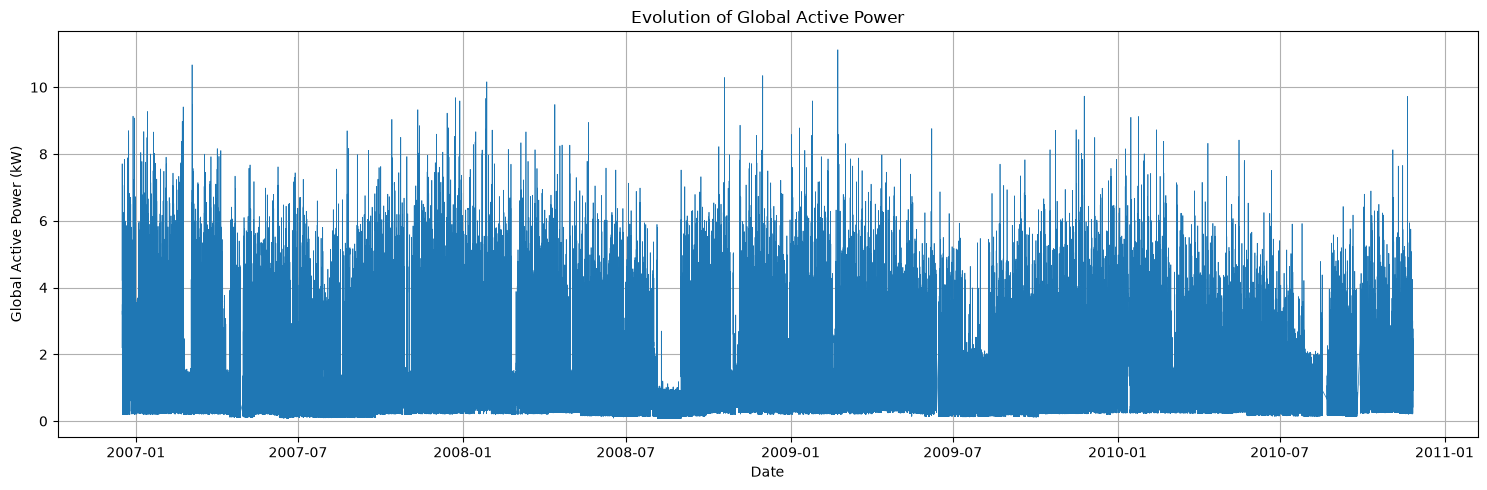

In [14]:
# Plot global active power over time
plt.figure(figsize=(15, 5))

plt.plot(
    df_clean["Datetime"],
    df_clean["Global_active_power"],
    linewidth=0.5
)

plt.title("Evolution of Global Active Power")
plt.xlabel("Date")
plt.ylabel("Global Active Power (kW)")

plt.grid(True)
plt.tight_layout()
plt.show()

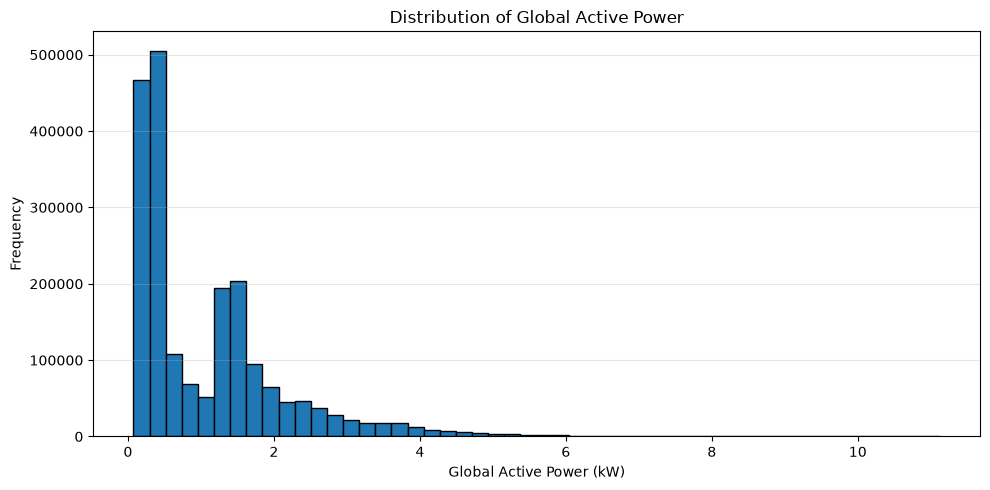

In [15]:
plt.figure(figsize=(10, 5))

plt.hist(
    df_clean["Global_active_power"],
    bins=50,
    edgecolor="black"
)

plt.title("Distribution of Global Active Power")
plt.xlabel("Global Active Power (kW)")
plt.ylabel("Frequency")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

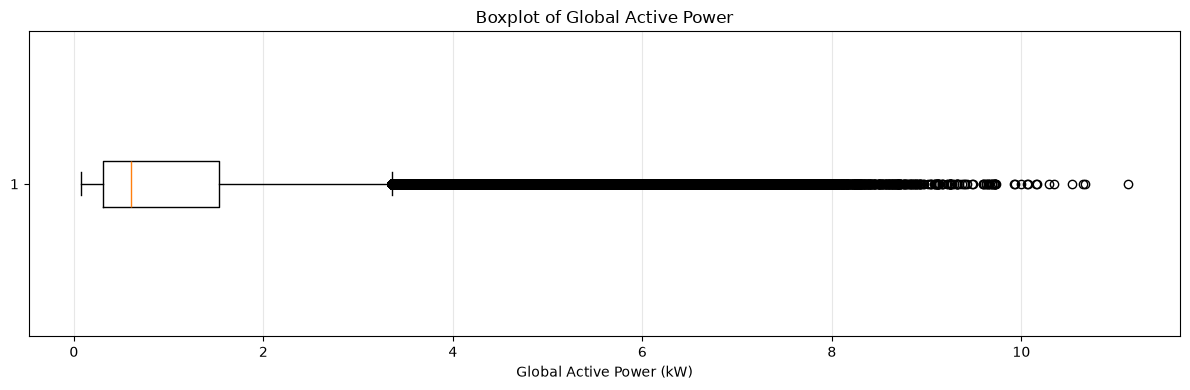

In [16]:
plt.figure(figsize=(12, 4))

plt.boxplot(
    df_clean["Global_active_power"],
    orientation="horizontal",
    showfliers=True
)

plt.title("Boxplot of Global Active Power")
plt.xlabel("Global Active Power (kW)")
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

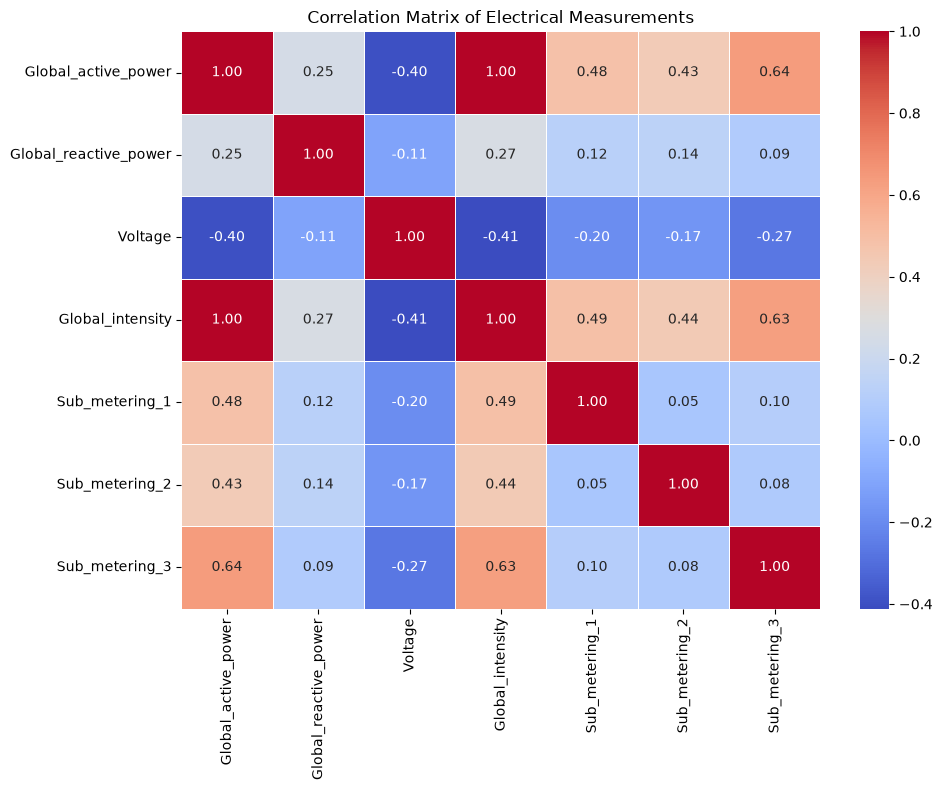

In [17]:
import seaborn as sns

# Calculate correlation matrix
corr_matrix = df_clean[numeric_columns].corr()

# Visualize correlation matrix
plt.figure(figsize=(10, 8))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Matrix of Electrical Measurements")
plt.tight_layout()
plt.show()

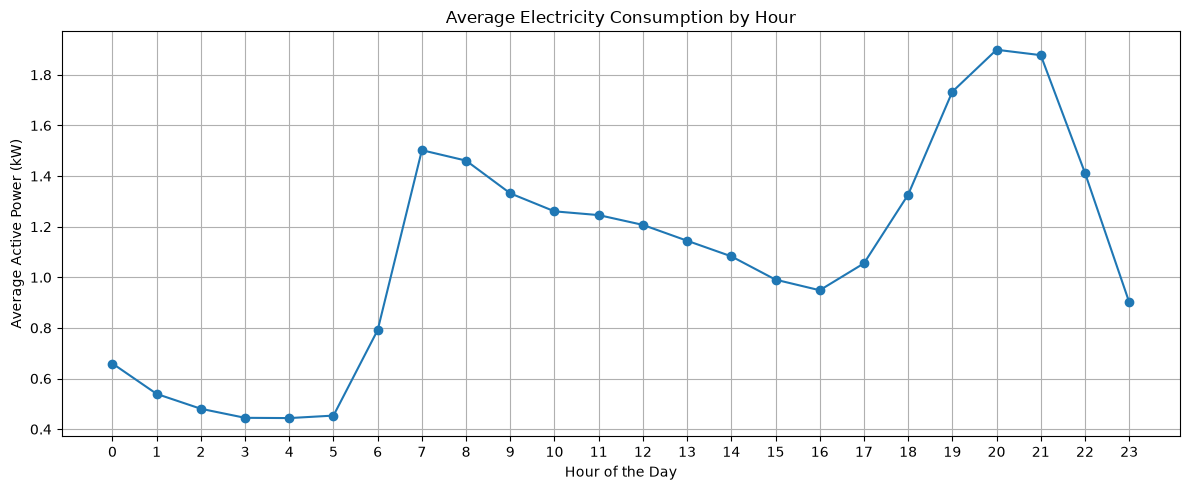

In [18]:
# Calculate average consumption for each hour
hourly_consumption = (
    df_clean.groupby(df_clean["Datetime"].dt.hour)
    ["Global_active_power"]
    .mean()
)

# Plot hourly consumption
plt.figure(figsize=(12, 5))

plt.plot(
    hourly_consumption.index,
    hourly_consumption.values,
    marker="o"
)

plt.title("Average Electricity Consumption by Hour")
plt.xlabel("Hour of the Day")
plt.ylabel("Average Active Power (kW)")

plt.xticks(range(24))
plt.grid(True)
plt.tight_layout()
plt.show()

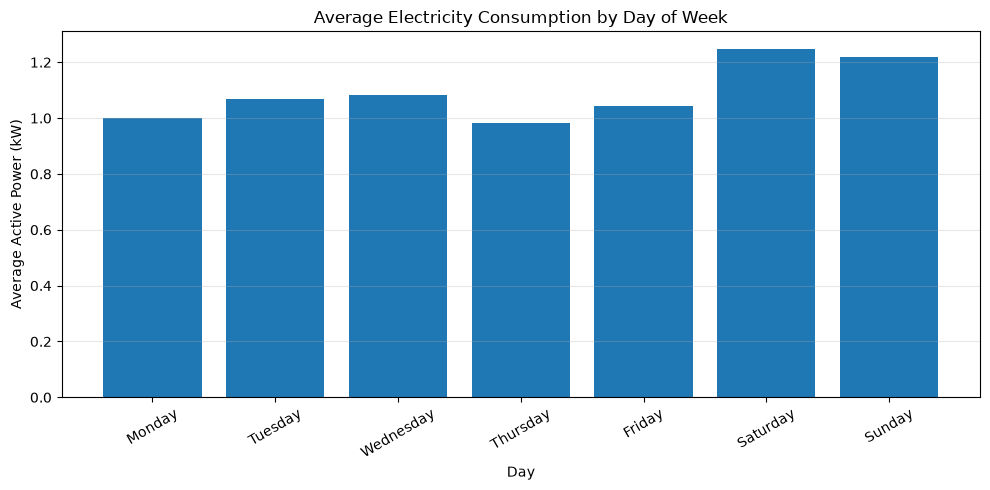

In [19]:
# Calculate average consumption by day of week
daily_consumption = (
    df_clean.groupby(df_clean["Datetime"].dt.day_of_week)
    ["Global_active_power"]
    .mean()
)

# Plot
plt.figure(figsize=(10, 5))

days = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

plt.bar(days, daily_consumption.values)

plt.title("Average Electricity Consumption by Day of Week")
plt.xlabel("Day")
plt.ylabel("Average Active Power (kW)")

plt.xticks(rotation=30)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

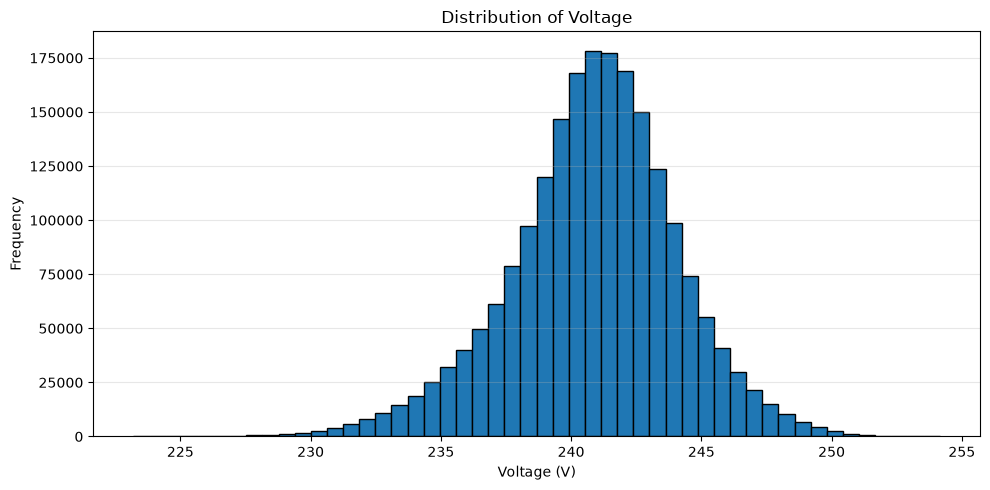

count    2.049280e+06
mean     2.408399e+02
std      3.239987e+00
min      2.232000e+02
25%      2.389900e+02
50%      2.410100e+02
75%      2.428900e+02
max      2.541500e+02
Name: Voltage, dtype: float64


In [20]:
plt.figure(figsize=(10, 5))

plt.hist(
    df_clean["Voltage"],
    bins=50,
    edgecolor="black"
)

plt.title("Distribution of Voltage")
plt.xlabel("Voltage (V)")
plt.ylabel("Frequency")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print(df_clean["Voltage"].describe())

count    2.049280e+06
mean     1.237145e-01
std      1.127220e-01
min      0.000000e+00
25%      4.800000e-02
50%      1.000000e-01
75%      1.940000e-01
max      1.390000e+00
Name: Global_reactive_power, dtype: float64


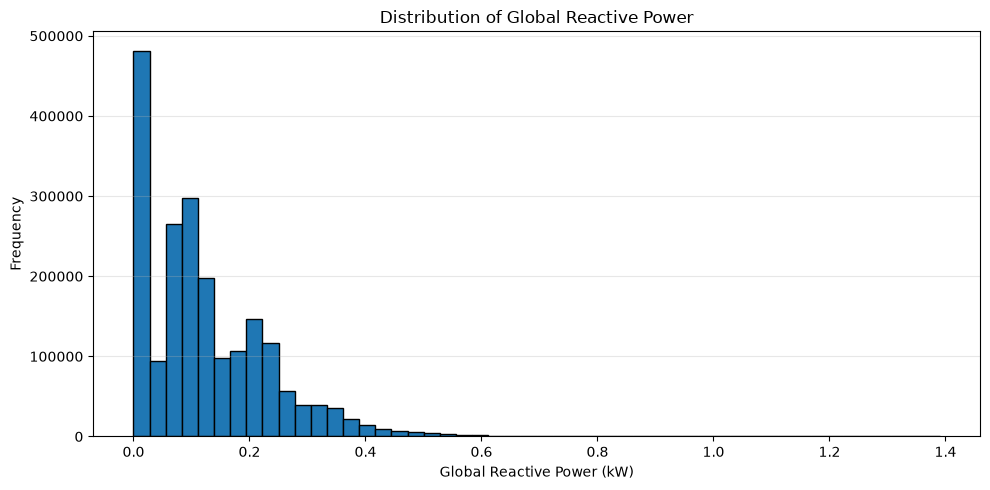

In [21]:
# Statistics
print(df_clean["Global_reactive_power"].describe())

# Histogram
plt.figure(figsize=(10, 5))

plt.hist(
    df_clean["Global_reactive_power"],
    bins=50,
    edgecolor="black"
)

plt.title("Distribution of Global Reactive Power")
plt.xlabel("Global Reactive Power (kW)")
plt.ylabel("Frequency")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

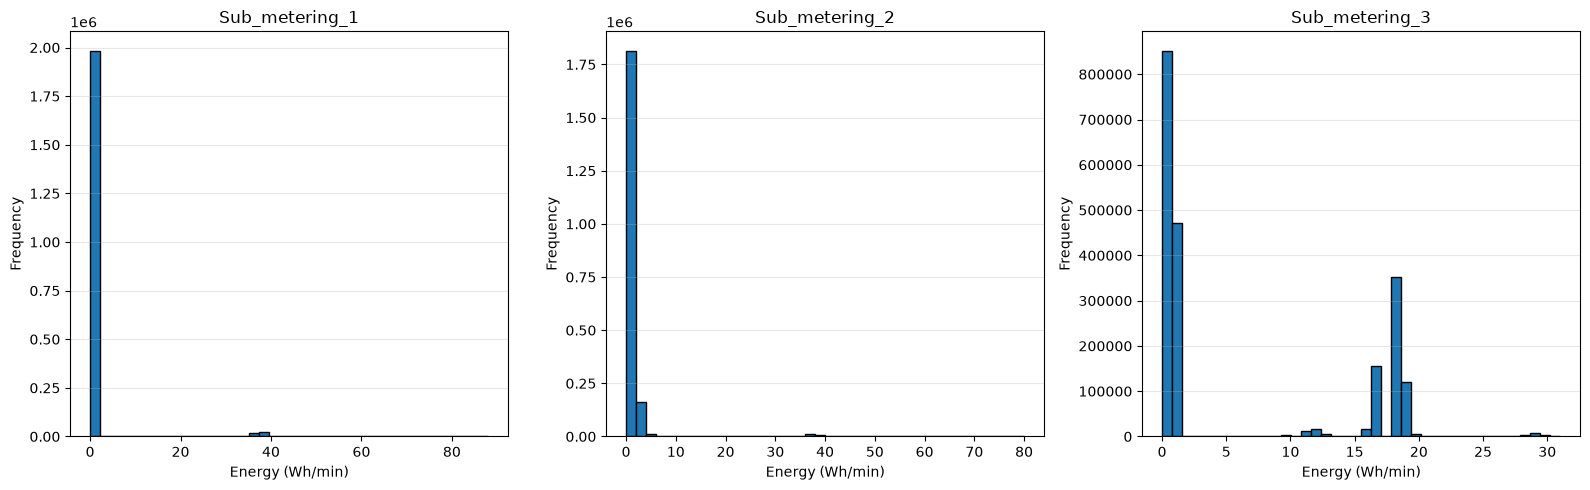

       Sub_metering_1  Sub_metering_2  Sub_metering_3
count    2.049280e+06    2.049280e+06    2.049280e+06
mean     1.121923e+00    1.298520e+00    6.458447e+00
std      6.153031e+00    5.822026e+00    8.437154e+00
min      0.000000e+00    0.000000e+00    0.000000e+00
25%      0.000000e+00    0.000000e+00    0.000000e+00
50%      0.000000e+00    0.000000e+00    1.000000e+00
75%      0.000000e+00    1.000000e+00    1.700000e+01
max      8.800000e+01    8.000000e+01    3.100000e+01


In [22]:
submetering_columns = [
    "Sub_metering_1",
    "Sub_metering_2",
    "Sub_metering_3"
]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for i, col in enumerate(submetering_columns):
    axes[i].hist(df_clean[col], bins=40, edgecolor="black")
    axes[i].set_title(col)
    axes[i].set_xlabel("Energy (Wh/min)")
    axes[i].set_ylabel("Frequency")
    axes[i].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

# Statistical summary
print(df_clean[submetering_columns].describe())

In [23]:
# Calculate total active energy per minute (Wh)
df_clean["Global_energy_Wh"] = (
    df_clean["Global_active_power"] * 1000 / 60
)

# Sum of the three sub-meters
df_clean["Sub_metering_total"] = (
    df_clean["Sub_metering_1"]
    + df_clean["Sub_metering_2"]
    + df_clean["Sub_metering_3"]
)

# Estimate energy consumed by other appliances
df_clean["Other_energy_Wh"] = (
    df_clean["Global_energy_Wh"]
    - df_clean["Sub_metering_total"]
)

# Statistical analysis
print(df_clean["Other_energy_Wh"].describe())

# Count negative values
print(
    "\nNegative values:",
    (df_clean["Other_energy_Wh"] < 0).sum()
)

count    2.049280e+06
mean     9.314693e+00
std      9.585916e+00
min     -2.400000e+00
25%      3.800000e+00
50%      5.500000e+00
75%      1.036667e+01
max      1.248333e+02
Name: Other_energy_Wh, dtype: float64

Negative values: 1050


In [24]:
# Select observations with negative remaining energy
negative_energy = df_clean[
    df_clean["Other_energy_Wh"] < 0
]

# Display first 10 observations
print(
    negative_energy[
        [
            "Datetime",
            "Global_energy_Wh",
            "Sub_metering_total",
            "Other_energy_Wh"
        ]
    ].head(10)
)

# Check the percentage of negative values
percentage = (
    len(negative_energy) / len(df_clean)
) * 100

print("\nPercentage of negative values:", percentage, "%")

                  Datetime  Global_energy_Wh  Sub_metering_total  \
176571 2007-04-18 08:24:00         49.866667                50.0   
176573 2007-04-18 08:26:00         25.900000                27.0   
183805 2007-04-23 08:58:00         33.566667                34.0   
196839 2007-05-05 00:15:00          5.633333                 6.0   
199199 2007-05-06 15:35:00         13.800000                14.0   
263502 2007-06-20 08:00:00         19.900000                20.0   
263506 2007-06-20 08:04:00         21.700000                22.0   
263569 2007-06-20 09:07:00         42.433333                43.0   
273552 2007-06-27 07:30:00         51.833333                52.0   
273987 2007-06-27 14:45:00          4.466667                 5.0   

        Other_energy_Wh  
176571        -0.133333  
176573        -1.100000  
183805        -0.433333  
196839        -0.366667  
199199        -0.200000  
263502        -0.100000  
263506        -0.300000  
263569        -0.566667  
273552        -0.

In [25]:
# Preserve original calculated values
# Create a non-negative version
df_clean["Other_energy_Wh_corrected"] = (
    df_clean["Other_energy_Wh"].clip(lower=0)
)

# Verify correction
print(
    "Negative values before:",
    (df_clean["Other_energy_Wh"] < 0).sum()
)

print(
    "Negative values after:",
    (df_clean["Other_energy_Wh_corrected"] < 0).sum()
)

Negative values before: 1050
Negative values after: 0


In [26]:
# Calculate time difference between consecutive measurements
time_diff = df_clean["Datetime"].diff()

# Convert differences into minutes
time_diff_minutes = time_diff.dt.total_seconds() / 60

# Analyze interruptions
print("Normal intervals (1 minute):",
      (time_diff_minutes == 1).sum())

print("Intervals greater than 1 minute:",
      (time_diff_minutes > 1).sum())

print("Maximum time gap:",
      time_diff.max())

print("\nLargest time gaps:")
print(
    time_diff_minutes.nlargest(10)
)

Normal intervals (1 minute): 2049208
Intervals greater than 1 minute: 71
Maximum time gap: 5 days 00:27:00

Largest time gaps:
1916303    7227.0
1964211    5238.0
190488     3724.0
1305243    3306.0
1608618    3130.0
1701305    2028.0
1390044     892.0
300030       84.0
1039605      71.0
300039       48.0
Name: Datetime, dtype: float64


In [27]:
# Identify gaps greater than one minute
gap_mask = time_diff_minutes > 1

# Create a table of interruptions
gaps = pd.DataFrame({
    "Previous_datetime": df_clean["Datetime"].shift(1)[gap_mask],
    "Current_datetime": df_clean["Datetime"][gap_mask],
    "Gap_minutes": time_diff_minutes[gap_mask]
})

# Sort from largest to smallest
gaps = gaps.sort_values(
    by="Gap_minutes",
    ascending=False
)

print("Number of interruptions:", len(gaps))
display(gaps)

Number of interruptions: 71


,Previous_datetime,Current_datetime,Gap_minutes
1916303,2010-08-17 21:01:00,2010-08-22 21:28:00,7227.0
1964211,2010-09-25 03:55:00,2010-09-28 19:13:00,5238.0
190488,2007-04-28 00:20:00,2007-04-30 14:24:00,3724.0
1305243,2009-06-13 00:29:00,2009-06-15 07:35:00,3306.0
1608618,2010-01-12 14:52:00,2010-01-14 19:02:00,3130.0
...,...,...,...
1778070,2010-05-13 21:04:00,2010-05-13 21:06:00,2.0
1845496,2010-06-29 16:52:00,2010-06-29 16:54:00,2.0
1821059,2010-06-12 17:34:00,2010-06-12 17:36:00,2.0
1868395,2010-07-15 14:32:00,2010-07-15 14:34:00,2.0


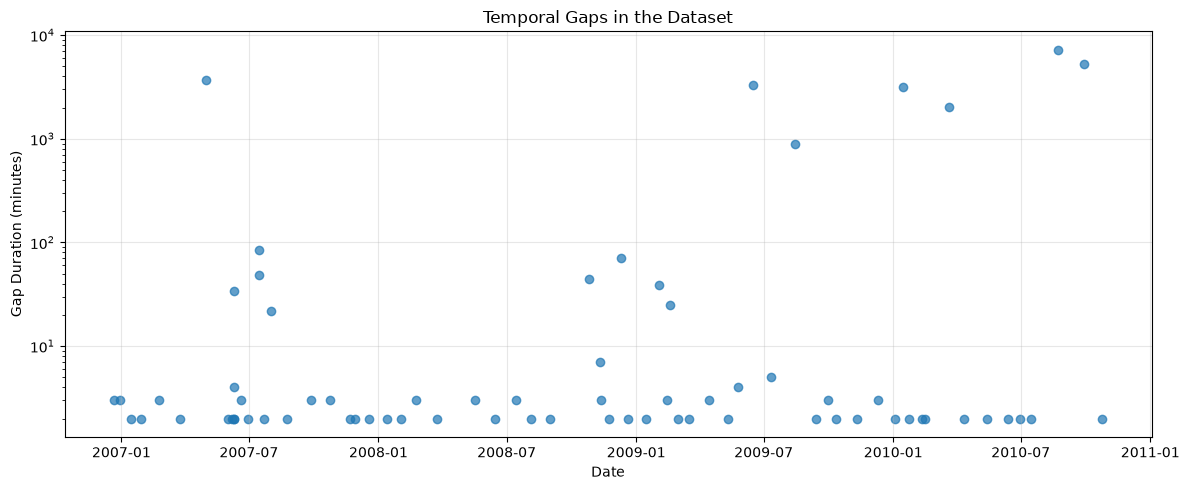

In [28]:
plt.figure(figsize=(12, 5))

plt.scatter(
    gaps["Current_datetime"],
    gaps["Gap_minutes"],
    alpha=0.7
)

plt.title("Temporal Gaps in the Dataset")
plt.xlabel("Date")
plt.ylabel("Gap Duration (minutes)")

plt.yscale("log")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# Rapport d'exploration des données (EDA)

## 1. Présentation du dataset

Le dataset utilisé dans ce projet est **Individual Household Electric Power Consumption**, publié sur la plateforme UCI Machine Learning Repository.

Il contient des mesures de consommation électrique d'un foyer individuel, enregistrées à une fréquence d'une minute.

- **Période :** du 16 décembre 2006 au 26 novembre 2010.
- **Nombre initial de lignes :** 2 075 259.
- **Nombre de variables initiales :** 9.
- **Fréquence des mesures :** une minute.
- **Type de données :** séries temporelles de consommation électrique.

**Source :** https://archive.ics.uci.edu/dataset/235/individual+household+electric+power+consumption

Ce dataset sera utilisé pour étudier les habitudes de consommation, entraîner des modèles de prédiction et analyser les comportements électriques inhabituels.


## 2. Structure et caractéristiques des données

Le dataset contient initialement 2 075 259 lignes et 9 colonnes.

Les variables sont :

| Variable | Description | Unité |
|---|---|---|
| Date | Date de mesure | - |
| Time | Heure de mesure | - |
| Global_active_power | Puissance active globale | kW |
| Global_reactive_power | Puissance réactive globale | kW |
| Voltage | Tension électrique | V |
| Global_intensity | Intensité électrique globale | A |
| Sub_metering_1 | Consommation du sous-compteur 1 (cuisine) | Wh/min |
| Sub_metering_2 | Consommation du sous-compteur 2 (buanderie) | Wh/min |
| Sub_metering_3 | Consommation du sous-compteur 3 (chauffe-eau et climatisation) | Wh/min |

Après le nettoyage, le dataset contient 2 049 280 lignes et 10 colonnes, avec la variable supplémentaire `Datetime`, créée à partir de `Date` et `Time`.


## 3. Nettoyage des données

### 3.1 Traitement des valeurs manquantes

Le dataset initial contenait 25 979 lignes dans lesquelles les sept variables électriques étaient entièrement manquantes.

Ces valeurs étaient représentées par le symbole `?`.

Nous avons remplacé ces symboles par des valeurs NaN, puis supprimé les lignes dont toutes les mesures électriques étaient manquantes.

### 3.2 Conversion des types de données

Les variables électriques ont été converties en types numériques (`float64`).

Une nouvelle colonne `Datetime` a été créée en combinant les colonnes `Date` et `Time`, afin de faciliter les analyses temporelles.

### 3.3 Vérification de la qualité des données

Après le nettoyage :

- Nombre de lignes restantes : 2 049 280.
- Nombre de colonnes : 10.
- Valeurs manquantes restantes : 0.
- Doublons temporels : 0.
- Données triées chronologiquement : oui.

### 3.4 Décision concernant les valeurs extrêmes

Les valeurs extrêmes de consommation ont été conservées, car elles peuvent représenter des pics réels de consommation électrique et être utiles pour la détection des anomalies.


## 4. Analyse statistique descriptive

L'analyse statistique descriptive permet de comprendre la distribution et les caractéristiques générales des variables électriques.

Les principales observations sont :

- **Global_active_power :** la consommation moyenne est relativement faible, mais des pics importants peuvent atteindre environ 11 kW.
- **Global_reactive_power :** la moyenne est d'environ 0,124 kW, avec une distribution asymétrique.
- **Voltage :** la tension moyenne est d'environ 240,84 V, avec des valeurs généralement concentrées autour de 239 à 243 V.
- **Sub_metering_1 :** la moyenne est d'environ 1,12 Wh/min.
- **Sub_metering_2 :** la moyenne est d'environ 1,30 Wh/min.
- **Sub_metering_3 :** la moyenne est d'environ 6,46 Wh/min.

Les distributions présentent une asymétrie à droite pour plusieurs variables, ce qui indique la présence de valeurs élevées relativement rares.


## 5. Analyse de la consommation électrique

### 5.1 Évolution de la consommation

Le graphique temporel montre que la consommation électrique varie considérablement au cours de la période étudiée. Plusieurs pics dépassent 8 kW et certains atteignent environ 11 kW.

Ces variations peuvent correspondre à l'utilisation simultanée de plusieurs appareils électriques.

### 5.2 Distribution de la consommation

L'histogramme montre une distribution asymétrique à droite. La majorité des mesures correspondent à des niveaux de consommation faibles, tandis que les consommations élevées sont moins fréquentes.

Le boxplot révèle également plusieurs valeurs extrêmes. Elles ont été conservées, car elles peuvent représenter des situations réelles.

### 5.3 Consommation selon l'heure

La consommation moyenne est plus faible pendant la nuit, notamment entre minuit et 5 heures du matin.

Deux périodes de consommation plus importante apparaissent :
- Le matin, autour de 7 heures.
- Le soir, autour de 20 heures.

### 5.4 Consommation selon le jour de la semaine

Les moyennes observées sont généralement plus élevées pendant le week-end que pendant certains jours de la semaine.

Cela peut indiquer une utilisation plus importante des appareils électriques lorsque les occupants passent davantage de temps à la maison.




## 6. Analyse des variables électriques

### 6.1 Tension (Voltage)

La tension moyenne est d'environ 240,84 V. La majorité des mesures se situent entre 239 V et 243 V.

Quelques valeurs sont plus éloignées de cette zone, mais elles ne doivent pas être considérées automatiquement comme des erreurs.

### 6.2 Puissance réactive

La puissance réactive présente une distribution asymétrique à droite.

Sa moyenne est d'environ 0,124 kW et son maximum atteint 1,39 kW. La majorité des mesures correspondent à des valeurs relativement faibles.

### 6.3 Sous-compteurs électriques

Les trois sous-compteurs présentent des comportements différents :

- **Sub_metering_1 :** consommation moyenne de 1,12 Wh/min, principalement composée de valeurs nulles.
- **Sub_metering_2 :** consommation moyenne de 1,30 Wh/min, avec également de nombreuses valeurs nulles.
- **Sub_metering_3 :** consommation moyenne de 6,46 Wh/min, supérieure à celle des deux autres sous-compteurs.

Le troisième sous-compteur représente donc une part importante de la consommation mesurée par les sous-compteurs.


## 7. Analyse des corrélations

La matrice de corrélation permet d'étudier les relations linéaires entre les variables électriques.

Les principales observations sont :

- **Global_active_power et Global_intensity :** corrélation très forte de 1,00.
- **Global_active_power et Voltage :** corrélation négative de -0,40.
- **Global_active_power et Sub_metering_1 :** corrélation positive de 0,48.
- **Global_active_power et Sub_metering_2 :** corrélation positive de 0,43.
- **Global_active_power et Sub_metering_3 :** corrélation positive de 0,64.
- **Global_active_power et Global_reactive_power :** corrélation positive de 0,25.

Ces résultats montrent que les sous-compteurs sont liés à la consommation globale.

La forte corrélation entre la puissance active et l'intensité indique également une relation très importante entre ces deux variables. Il faudra tenir compte de cette redondance lors de la sélection des variables pour les modèles de Machine Learning.


## 8. Analyse des interruptions temporelles

L'analyse des intervalles entre deux mesures consécutives montre que le dataset ne possède pas une continuité temporelle parfaite.

Les résultats obtenus sont :

- Nombre d'intervalles normaux d'une minute : 2 049 208.
- Nombre d'interruptions supérieures à une minute : 71.
- Durée maximale d'une interruption : 7 227 minutes, soit environ 5 jours.

Ces interruptions peuvent être dues à des périodes d'absence de mesures dans la collecte des données.

Les décisions prises sont :

- Conserver les données disponibles après les interruptions.
- Ne pas remplacer artificiellement les longues périodes manquantes.
- Éviter de construire des séquences temporelles traversant ces interruptions lors de l'entraînement des modèles.

Cette précaution est importante pour garantir la qualité des données utilisées dans les modèles de prédiction.


## 9. Conclusions et recommandations pour le Machine Learning

L'exploration des données a permis de mieux comprendre les caractéristiques de la consommation électrique du foyer étudié.

Le dataset présente plusieurs caractéristiques intéressantes pour notre projet :
- Une forte variabilité de la consommation électrique.
- Des habitudes de consommation différentes selon l'heure et le jour.
- Des relations entre les variables électriques.
- Des pics de consommation pouvant être étudiés pour détecter des comportements inhabituels.
- Quelques interruptions temporelles à prendre en compte.

### Recommandations pour le Machine Learning

1. **Prédiction de consommation :** utiliser les mesures historiques et les caractéristiques temporelles.
2. **Détection d'anomalies :** conserver les pics de consommation pour étudier les comportements inhabituels.
3. **Préparation temporelle :** respecter l'ordre chronologique et éviter les séquences qui traversent les longues interruptions.
4. **Sélection des variables :** examiner la forte corrélation entre la puissance active et l'intensité afin d'éviter une redondance inutile.
5. **Évaluation des modèles :** utiliser une séparation chronologique entre les données d'entraînement et de test.

Cette exploration constitue une première étape dans la préparation des données pour les différents modèles de notre projet Smart_Energy_AI.



In [29]:

# Colonnes à conserver dans le dataset final

final_columns = [
    "Date",
    "Time",
    "Global_active_power",
    "Global_reactive_power",
    "Voltage",
    "Global_intensity",
    "Sub_metering_1",
    "Sub_metering_2",
    "Sub_metering_3",
    "Datetime"
]

# Création du dataset final
df_final = df_clean[final_columns].copy()

# Vérification
print("Dataset final shape:", df_final.shape)
print("\nMissing values:")
print(df_final.isnull().sum())

print("\nColumns:")
print(df_final.columns.tolist())


Dataset final shape: (2049280, 10)

Missing values:
Date                     0
Time                     0
Global_active_power      0
Global_reactive_power    0
Voltage                  0
Global_intensity         0
Sub_metering_1           0
Sub_metering_2           0
Sub_metering_3           0
Datetime                 0
dtype: int64

Columns:
['Date', 'Time', 'Global_active_power', 'Global_reactive_power', 'Voltage', 'Global_intensity', 'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3', 'Datetime']


In [30]:

import os

output_path = "../../01_Dataset/Processed/household_power_consumption_final.csv.gz"

df_final.to_csv(output_path, index=False, compression="gzip")

file_size = os.path.getsize(output_path) / (1024 * 1024)

print("Dataset saved successfully!")
print("File:", output_path)
print(f"File size: {file_size:.2f} MB")


Dataset saved successfully!
File: ../../01_Dataset/Processed/household_power_consumption_final.csv.gz
File size: 23.58 MB


In [31]:

# Recharger le fichier compressé
df_check = pd.read_csv(
    output_path,
    compression="gzip",
    parse_dates=["Datetime"]
)

# Vérifications
print("Shape:", df_check.shape)
print("Missing values:", df_check.isnull().sum().sum())
print("Datetime type:", df_check["Datetime"].dtype)

# Vérification automatique
assert df_check.shape == (2049280, 10)
assert df_check.isnull().sum().sum() == 0

print("\nDataset verification successful!")


Shape: (2049280, 10)
Missing values: 0
Datetime type: datetime64[us]

Dataset verification successful!
